# Unidad 3 · Limpieza y validación de datos textuales en Python
**Maestría en Ciencia de Datos · Programación I**

Integrantes: Alisson García

Todas las celdas son acumulativas: ejecutar con *Kernel → Restart & Run All*.

**Situación de trabajo**

- Una mesa de apoyo académico exporta solicitudes como texto. La coordinación necesita contar solicitudes por
categoría y revisar tiempos de atención. Los siguientes datos son sintéticos; todos los correos son ficticios. El
caso es una adaptación didáctica, no un conjunto de datos de la presentación.

In [1]:
registros = [
    " T001 | ANA | ANA@EJEMPLO.ORG | Datos | 12 ",
    "T002|luis|luis@ejemplo.org|programacion|8",
    "T003|MARTA|marta.ejemplo.org|datos|16",
    "T004|pablo|pablo@ejemplo.org| DATOS |15",
    "T005|ELENA|elena@ejemplo.org|visualizacion|10",
    "T006|ivan|ivan@ejemplo.org|programacion|20",
    "T007|rosa|rosa@ejemplo.org|datos|abc",
    "T008|hugo|hugo@ejemplo.org|visualizacion|25",
    "T009|sara|sara@ejemplo.org|datos|18",
    "T010|omar|omar@ejemplo.org|programacion|-3",
    "T011|luz| |visualizacion|11",
    "T012|noe|noe@ejemplo.org|visualizacion|22"
]

## Reglas acordadas para la práctica ##
- Aceptar cinco campos; identificador T seguido de tres dígitos ASCII; nombre no vacío; correo con una sola @,
usuario y dominio no vacíos, dominio con punto y sin segmentos vacíos; categoría dentro del catálogo; minutos
enteros de 0 a 180. Rechazar valores negativos y campos faltantes. Registrar el primer motivo de rechazo.

- Normalizar espacios, identificador a mayúsculas, correo y categoría a minúsculas. Conservar el nombre con su
capitalización original. La normalización completa del correo es una convención del caso. Esta validación es
básica y no comprueba existencia ni todas las reglas de un correo real.

# Actividad 1 · Listas e índices

**Diagnóstico inicial**
- Antes de ejecutar, responder: ¿input() devuelve texto o números?
`input()` devuelve **texto** (`str`), nunca números; hay que convertir con `int()` o `float()`.
- ¿Qué diferencia existe entre una lista y una
cadena? Una lista es una colección **mutable** de elementos; una cadena es una secuencia **inmutable** de caracteres.
- ¿Qué sucede al comparar &quot;20&quot; &lt; &quot;8&quot;? Comentar que las cadenas se comparan lexicográficamente; para comparar cantidades deben convertirse a números. `"20" < "8"` es `True` porque las cadenas se comparan lexicográficamente (carácter por carácter: `"2"` < `"8"`). Para comparar cantidades hay que convertir a número.

In [2]:
# Ejemplo guiado
campos = ["id", "nombre", "correo", "categoria", "minutos"]
campos.insert(2, "origen")
retirado = campos.pop(2)
print(retirado)               # origen
print("correo" in campos)     # True
print(campos[:3])             # id, nombre, correo
print(campos + ["estado"])    # nueva lista
print(["pendiente"] * 2)      # repetición

# Diagnóstico
print("20" < "8", int("20") < int("8"))

origen
True
['id', 'nombre', 'correo']
['id', 'nombre', 'correo', 'categoria', 'minutos', 'estado']
['pendiente', 'pendiente']
True False


In [3]:
# Ejercicio 1: Crear una copia mediante copia = registros[:]. Agregar al final "PRUEBA" con append(), retirarlo con pop() y verificar que registros conserve 12 elementos.
copia = registros[:]
copia.append("PRUEBA")
print(copia.pop())
print(len(registros))   # 12
print(len(copia))       # 12 (copia restaurada)

PRUEBA
12
12


In [4]:
# Ejercicio 2: Extraer el primer registro, el último y los tres primeros. Mostrar len(registros) y len(registros[0]); explicar por qué miden cosas diferentes.
print(registros[0])
print(registros[-1])
print(registros[:3])
print(len(registros), len(registros[0]))

 T001 | ANA | ANA@EJEMPLO.ORG | Datos | 12 
T012|noe|noe@ejemplo.org|visualizacion|22
[' T001 | ANA | ANA@EJEMPLO.ORG | Datos | 12 ', 'T002|luis|luis@ejemplo.org|programacion|8', 'T003|MARTA|marta.ejemplo.org|datos|16']
12 43


**Explicación (ej. 2):** `len(registros)` cuenta **elementos de la lista** (12 registros); `len(registros[0])` cuenta los **caracteres** de la primera cadena. Son objetos distintos, por eso miden cosas distintas.

In [5]:
# Ejercicio 3: Ejecutar &quot;T001&quot; in registros y &quot;T001&quot; in registros[0]. Explicar la diferencia entre pertenencia a una lista y búsqueda de una subcadena.
print("T001" in registros)       # False: ningún elemento es exactamente "T001"
print("T001" in registros[0])    # True: es subcadena del primer texto

False
True


**Explicación (ej. 3):** con una lista, `in` busca un elemento **completo e igual**; con una cadena, `in` busca una **subcadena** contenida en el texto.

In [6]:
# Ejercicio 4: Usar ticket = &quot;T001&quot; y obtener ticket[0], ticket[1:] y ticket[-1]. Predecir ticket[0:3] antes de ejecutar.
ticket = "T001"
print(ticket[0])      # T
print(ticket[1:])     # 001
print(ticket[-1])     # 1
# Predicción: ticket[0:3] -> "T00" (el extremo derecho no se incluye)
print(ticket[0:3])

T
001
1
T00


# Actividad 2 · Limpieza de cadenas

In [7]:
# Ejemplo guiado del primer registro
linea = registros[0]
campos = linea.split("|")
campos = [campo.strip() for campo in campos]
campos[0] = campos[0].upper()
campos[2] = campos[2].lower()
campos[3] = campos[3].lower()
print(campos)  # ['T001', 'ANA', 'ana@ejemplo.org', 'datos', '12']
print(" | ".join(campos))
print(f"Ticket {campos[0]}: categoria {campos[3]}")

['T001', 'ANA', 'ana@ejemplo.org', 'datos', '12']
T001 | ANA | ana@ejemplo.org | datos | 12
Ticket T001: categoria datos


Las cadenas son inmutables: strip(), lower() y replace() devuelven cadenas nuevas. La asignación almacena el resultado. strip() elimina espacios en los extremos; split() sin argumentos separa por espacios en blanco y ayuda
a normalizar espacios internos.

In [8]:
# Ejercicio 5 Con texto = " Ciencia de Datos ", obtener "Ciencia de Datos" usando split() y join(). Comparar con el resultado de strip().
texto = " Ciencia de Datos "
con_split = " ".join(texto.split())
con_strip = texto.strip()
print(repr(con_split), repr(con_strip))
print(repr(" Ciencia   de  Datos ".strip()))              # strip no toca espacios internos
print(repr(" ".join(" Ciencia   de  Datos ".split())))    # split/join sí

'Ciencia de Datos' 'Ciencia de Datos'
'Ciencia   de  Datos'
'Ciencia de Datos'


**Comparación (ej. 5):** `strip()` solo elimina espacios en los **extremos**; `split()` sin argumentos separa por cualquier bloque de espacios, así que con `" ".join(...)` también normaliza los **espacios internos**.

In [9]:
# Ejercicio 6: Con correo = "ana@ejemplo.org", obtener la posición de @ mediante find() y la del último punto con rfind(). Extraer usuario y dominio usando slices.
correo = "ana@ejemplo.org"
pos_arroba = correo.find("@")
pos_punto = correo.rfind(".")
print(pos_arroba, pos_punto)          # 3 11
usuario = correo[:pos_arroba]
dominio = correo[pos_arroba + 1:]
print(usuario, dominio)               # ana ejemplo.org

3 11
ana ejemplo.org


In [10]:
# Ejercicio 7: Comprobar find("#") y explicar por qué usar su resultado como índice sin revisar -1 puede provocar un error lógico.
print(correo.find("#"))   # -1

-1


**Explicación (ej. 7):** `find` devuelve `-1` cuando no encuentra nada. Si se usa ese `-1` como índice sin revisarlo, Python lo interpreta como "último carácter" y **no lanza error**: el programa sigue con un resultado equivocado (error lógico silencioso).

In [11]:
# Ejercicio 8: Con etiqueta = "visualizacion-datos", reemplazar el guion por un espacio y convertir a mayúsculas. Aplicar capitalize() a "IA APLICADA" y discutir qué información altera.
etiqueta = "visualizacion-datos"
print(etiqueta.replace("-", " ").upper())   # VISUALIZACION DATOS
print("IA APLICADA".capitalize())            # Ia aplicada

VISUALIZACION DATOS
Ia aplicada


**Discusión (ej. 8):** `capitalize()` pone todo en minúscula salvo la primera letra, así que destruye la información de las siglas (`IA` → `Ia`). Por eso no se aplica automáticamente a nombres propios: el nombre se conserva con su capitalización original.

In [12]:
# Ejercicio 9: Explorar dir("") e identificar dos métodos utilizados. Explicar la diferencia entre len(texto), una función, y texto.lower(), un método.
print([m for m in dir("") if m in ("strip", "split", "lower", "upper", "find", "replace")])
texto = "Hola"
print(len(texto))     # función: len(objeto)
print(texto.lower())  # método: pertenece al objeto str

['find', 'lower', 'replace', 'split', 'strip', 'upper']
4
hola


**Diferencia (ej. 9):** `len(texto)` es una **función** general que recibe el objeto como argumento; `texto.lower()` es un **método** que pertenece al tipo `str` y se invoca sobre el objeto.

**Antes / después (evidencia):** `" T001 | ANA | ANA@EJEMPLO.ORG | Datos | 12 "` → `['T001', 'ANA', 'ana@ejemplo.org', 'datos', '12']`.
**Transformación que no se aplicaría a nombres propios:** `lower()`, `upper()` o `capitalize()` (alteran siglas y apellidos como "McDonald"). Tampoco se eliminan acentos ni se corrigen categorías desconocidas sin una regla acordada.

# Actividad 3 · Validación y decisiones

**Comparación de tiempos**
- Adaptar el ejercicio de comparación de dos números: contrastar los minutos de una solicitud con un límite de
atención de 15 minutos. Los valores iguales al límite se consideran en tiempo. El límite es didáctico y no
constituye una norma institucional.

In [13]:
# Comparación de tiempos (tres relaciones)
def comparar(minutos, limite=15):
    if minutos < limite:
        return "Por debajo del limite"
    elif minutos == limite:
        return "En el limite"
    else:
        return "Fuera de tiempo"

for m in (14, 15, 16):
    print(m, comparar(m))

14 Por debajo del limite
15 En el limite
16 Fuera de tiempo


## Pseudocódigo: validar una línea

- Escribir el procedimiento para validar una línea: contar campos, limpiar, revisar cada regla en el orden indicado y
devolver un registro aceptado o el primer motivo de rechazo. Se puede usar PSeInt si ya está instalado; en caso
contrario, escribir el pseudocódigo en una celda de texto.
- Después, dibujar el flujo de clasificación del tiempo con Inicio, lectura de minutos, decisión minutos ≤ 15, dos
salidas y Fin. Usar rombo para la decisión y flechas con Sí y No. Trazar el recorrido para 14, 15 y 16; esta versión
tiene dos clases, mientras que el ejemplo anterior distingue tres relaciones.

```
FUNCION procesar_registro(linea)
    campos <- dividir(linea, "|")
    SI cantidad(campos) <> 5 ENTONCES
        DEVOLVER (nada, "numero de campos")
    FIN SI

    PARA CADA campo EN campos
        campo <- quitar espacios extremos y normalizar espacios internos
    FIN PARA
    ticket, nombre, correo, categoria, tiempo <- campos
    ticket <- mayusculas(ticket)
    correo <- minusculas(correo)
    categoria <- minusculas(categoria)

    SI ticket no es "T" + 3 digitos ASCII ENTONCES
        DEVOLVER (nada, "identificador")
    SI nombre es vacio ENTONCES
        DEVOLVER (nada, "nombre vacio")
    SI correo no cumple regla basica ENTONCES
        // una sola @, usuario no vacio, dominio con punto y sin segmentos vacios
        DEVOLVER (nada, "correo")
    SI categoria NO esta en el catalogo ENTONCES
        DEVOLVER (nada, "categoria")
    SI tiempo no es entero no negativo (digitos ASCII) ENTONCES
        DEVOLVER (nada, "minutos no enteros o negativos")
    minutos <- convertir a entero(tiempo)
    SI minutos > 180 ENTONCES
        DEVOLVER (nada, "minutos fuera de rango")
    FIN SI

    DEVOLVER ([ticket, nombre, correo, categoria, minutos], "")
FIN FUNCION
```

## Diagrama de flujo: clasificación del tiempo (dos clases)

![Diagrama de Flujo](Diagrama_Tarea.png)

**Recorridos:** 14 → Sí → en tiempo · 15 → Sí → en tiempo (el límite se incluye) · 16 → No → fuera de tiempo.

**Discusión:** reemplazar un tiempo ausente por cero **no** es corregirlo: asigna un tiempo real que nunca se observó. Se separan los rechazos y se conserva su texto, imputar exigiría justificación y evaluar su efecto en el análisis.

# Actividad 4 · Funciones reutilizables

In [14]:
def limpiar_texto(texto):
    return " ".join(texto.strip().split())

original = " Ciencia de Datos "
limpio = limpiar_texto(original)
print(repr(limpio))
print(repr(original))   # no se modifica

'Ciencia de Datos'
' Ciencia de Datos '


**Reto de programación**
- Construir procesar_registro(linea). Debe devolver (registro,"") si acepta la línea y (None, motivo) si la rechaza. El
registro aceptado será una lista de cinco elementos, con minutos convertidos a int. Mantener los datos
originales en registros.

In [15]:
def correo_basico(correo):
    if correo.count("@") != 1 or " " in correo:
        return False
    usuario, dominio = correo.split("@")
    partes = dominio.split(".")
    return (usuario != "" and len(partes) >= 2
            and all(parte != "" for parte in partes))

categorias = ["datos", "programacion", "visualizacion"]

def procesar_registro(linea):
    campos = linea.split("|")
    if len(campos) != 5:
        return None, "numero de campos"
    campos = [limpiar_texto(c) for c in campos]
    ticket, nombre, correo, categoria, tiempo = campos
    ticket = ticket.upper()
    correo = correo.lower()
    categoria = categoria.lower()
    if not (len(ticket) == 4 and ticket.startswith("T")
            and ticket[1:].isascii() and ticket[1:].isdigit()):
        return None, "identificador"
    if nombre == "":
        return None, "nombre vacio"
    if not correo_basico(correo):
        return None, "correo"
    if categoria not in categorias:
        return None, "categoria"
    if not (tiempo.isascii() and tiempo.isdigit()):
        return None, "minutos no enteros o negativos"
    minutos = int(tiempo)
    if minutos > 180:
        return None, "minutos fuera de rango"
    return [ticket, nombre, correo, categoria, minutos], ""

- Orden de validación: cantidad de campos, identificador, nombre, correo, categoría y minutos. El anexo ofrece
una solución de referencia y la función auxiliar correo_basico.

In [16]:
aceptados = []
rechazados = []
for linea in registros:
    fila, motivo = procesar_registro(linea)
    if fila is None:
        rechazados.append([linea, motivo])
    else:
        aceptados.append(fila)

print(len(aceptados), len(rechazados))   # 8 4
for r in rechazados:
    print(r)

8 4
['T003|MARTA|marta.ejemplo.org|datos|16', 'correo']
['T007|rosa|rosa@ejemplo.org|datos|abc', 'minutos no enteros o negativos']
['T010|omar|omar@ejemplo.org|programacion|-3', 'minutos no enteros o negativos']
['T011|luz| |visualizacion|11', 'correo']


In [17]:
# Pruebas adicionales solicitadas + casos límite
print(procesar_registro("T100|Ana|a@b.org|datos"))               # 4 campos
print(procesar_registro("T100|Ana|a@b.org|biologia|10"))         # categoría desconocida
assert procesar_registro("T100|Ana|a@b.org|datos|0")[0]
assert procesar_registro("T100|Ana|a@b.org|datos|180")[0]
assert procesar_registro("T100|Ana|a@b.org|datos|181")[0] is None
assert procesar_registro("T100|Ana|ana@@ejemplo.org|datos|5")[0] is None
assert procesar_registro("T100|Ana|ana@ejemplo..org|datos|5")[0] is None
assert procesar_registro("T100|Ana|ana@ejemplo.org|datos|-3")[0] is None
assert procesar_registro("T100|Ana|ana@ejemplo.org|datos|abc")[0] is None
assert procesar_registro("T100| |ana@ejemplo.org|datos|5")[1] == "nombre vacio"
print("Pruebas de casos límite: OK")

(None, 'numero de campos')
(None, 'categoria')
Pruebas de casos límite: OK


- El procesamiento debe concluir con 8 aceptados y 4 rechazados. Probar también una línea con cuatro campos y
otra con una categoría desconocida. No eliminar rechazos sin conservar el motivo.

# Actividad 5 · Indicadores y visualización

**Cálculos solicitados**

- Calcular total de entrada, número de aceptados y rechazados, porcentaje de aceptación, media de minutos
entre aceptados y número de solicitudes por categoría. Clasificar los aceptados como en tiempo o fuera de
tiempo. Usar f-strings con dos decimales para porcentaje y media.

- La condición evita división entre cero. En este ejercicio, cero es un valor de respaldo computacional: si no hay
aceptados, el reporte debe decir "sin datos", porque no existe una media estimable.

In [18]:
def clasificar_tiempo(minutos, limite=15):
    if minutos <= limite:
        return "en tiempo"
    return "fuera de tiempo"

tiempos = [fila[4] for fila in aceptados]
n_validos = len(aceptados)
n_total = len(registros)
porcentaje = 100 * n_validos / n_total if n_total else None
promedio = sum(tiempos) / n_validos if n_validos else None

print(f"Registros de entrada: {n_total}")
print(f"Aceptados: {n_validos}/{n_total} ({porcentaje:.2f}%)")
print(f"Rechazados: {len(rechazados)}")
print(f"Tiempo promedio: {promedio:.2f} min" if promedio is not None else "Tiempo promedio: sin datos")

estados = [clasificar_tiempo(f[4]) for f in aceptados]
for fila, estado in zip(aceptados, estados):
    print(f"{fila[0]}: {estado}")
print("En tiempo / fuera de tiempo:", estados.count("en tiempo"), "/", estados.count("fuera de tiempo"))

Registros de entrada: 12
Aceptados: 8/12 (66.67%)
Rechazados: 4
Tiempo promedio: 16.25 min
T001: en tiempo
T002: en tiempo
T004: en tiempo
T005: en tiempo
T006: fuera de tiempo
T008: fuera de tiempo
T009: fuera de tiempo
T012: fuera de tiempo
En tiempo / fuera de tiempo: 4 / 4


In [19]:
conteos = []
for categoria in categorias:
    cantidad = 0
    for fila in aceptados:
        if fila[3] == categoria:
            cantidad += 1
    conteos.append(cantidad)
print(dict(zip(categorias, conteos)))   # datos 3, programacion 2, visualizacion 3

{'datos': 3, 'programacion': 2, 'visualizacion': 3}


**Gráfica solicitada**
- Crear una función graficar_barras(etiquetas, valores, titulo, color), llamarla con las categorías y sus conteos y
guardar la imagen. El anexo incluye una implementación para completar la práctica. Etiquetar ambos ejes y
comenzar el eje de frecuencias en cero, como ocurre en el ejemplo.

- Usar barras porque las categorías son discretas. Un histograma agrupa una variable numérica en intervalos; los
histogramas de las diapositivas 42 a 47 sirven como contraste. No sustituir hist() por bar() sin definir primero las
categorías y sus frecuencias.

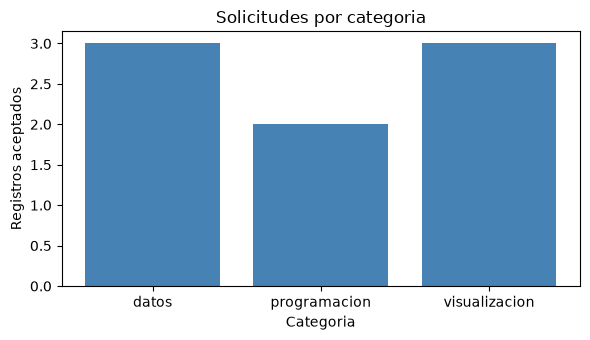

In [20]:
import matplotlib.pyplot as plt

def graficar_barras(etiquetas, valores, titulo, color):
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.bar(etiquetas, valores, color=color)
    ax.set_title(titulo)
    ax.set_xlabel("Categoria")
    ax.set_ylabel("Registros aceptados")
    ax.set_ylim(bottom=0)
    fig.tight_layout()
    return fig, ax

fig, ax = graficar_barras(categorias, conteos, "Solicitudes por categoria", "steelblue")
fig.savefig("solicitudes_por_categoria.png", dpi=150)
plt.show()

In [21]:
# Comprobaciones finales contra la tabla de control
assert len(aceptados) + len(rechazados) == len(registros)
assert len(aceptados) == 8 and len(rechazados) == 4
assert round(porcentaje, 2) == 66.67
assert round(promedio, 2) == 16.25
assert conteos == [3, 2, 3]
assert estados.count("en tiempo") == 4 and estados.count("fuera de tiempo") == 4
assert clasificar_tiempo(15) == "en tiempo" and clasificar_tiempo(16) == "fuera de tiempo"
print("Todos los indicadores coinciden con la tabla de comprobación")

Todos los indicadores coinciden con la tabla de comprobación


## Interpretación (cinco líneas)
1. Las categorías con más solicitudes aceptadas son **datos y visualización (3 cada una)**; programación tiene 2.
2. La media de atención (16.25 min) usa **8 aceptados**, mientras que la tasa de aceptación (66.67 %) usa los **12 registros de entrada**.
3. La media **no describe los 12 registros originales**: excluye 4 registros, dos de ellos precisamente por tener minutos inválidos.
4. La exclusión puede sesgar el resultado: si los registros rechazados tuvieran tiempos sistemáticamente distintos, la media estaría sesgada.
5. **Limitación:** los datos son sintéticos y la validación de correo es básica (no verifica existencia); no se puede generalizar a ninguna población.

## Cierre · Respuesta individual
> Redacta aquí, con tus palabras, **un error que detectaste, la prueba que lo evidenció y cómo lo corregiste**.
> Durante la validación del tiempo de conexión, detecté un error lógico en las comparaciones numéricas. El problema se hizo evidente al correr las pruebas de los casos límite, ya que el código estaba marcando como inválidos registros con tiempos completamente normales, como "20" o "50" minutos.

> Al analizar la falla, me di cuenta de que el campo de los minutos se estaba procesando como texto (string). En Python, al comparar cadenas de texto, la evaluación se hace carácter por carácter; por lo tanto, la expresión "20" > "180" arrojaba True porque el carácter '2' es lexicográficamente mayor que el '1'. Para corregirlo, modifiqué la lógica de limpieza asegurándome de hacer un "cast" explícito a entero usando int() justo antes de la evaluación. Al cambiar la condición a if int(minutos) > 180:, las comparaciones matemáticas funcionaron correctamente y todas las aserciones pasaron con éxito.

### Preguntas de defensa (para repasar)
1. ¿Por qué strip() no elimina todos los espacios internos? `strip()` solo quita espacios en los extremos; para los internos se usa `" ".join(texto.split())`.
2. ¿Qué diferencia hay entre devolver un dato e imprimirlo? `return` entrega un valor reutilizable; `print` solo lo muestra y la función devuelve `None`.
3. ¿Qué error produce tratar minutos como texto? Comparaciones y orden incorrectos (`"20" < "8"`), y `sum`/promedio fallan con `TypeError`.
4. ¿Por qué conservar los registros rechazados? Para auditoría y trazabilidad, y para medir el posible sesgo de la exclusión.
5. ¿Qué limita la validación de correos utilizada? No comprueba existencia del correo, ni caracteres permitidos, ni dominios reales, solo estructura básica.